# Comparative Analysis of BiLSTM, DistilBERT and BERT-base for Patient Sentiment Classification Using Drug Reviews (Binary: Negative vs Positive)

**Dataset:** Drugs.com reviews (UCI / Kaggle `jessicali9530/kuc-hackathon-winter-2018`)
**Task:** Binary sentiment from the 1–10 rating → **Negative (ratings 1–5)** and **Positive (ratings 6–10)** — 5 rating levels per class, no Neutral class
**Models:** BiLSTM (sequence learning) vs DistilBERT and BERT-base (Transformers)
**Metrics:** Accuracy, macro Precision, macro Recall, macro-F1, confusion matrices, McNemar significance test

**What this improved version changes (vs. the first draft)**
1. Uses *all* de-duplicated reviews (≈128k) instead of throwing away ~95k reviews to force a 11k-per-class balance → more data is the single biggest cure for overfitting.
2. Keeps the real class distribution and handles imbalance with a **class-weighted loss**, so the smaller Negative class is not ignored.
3. **Label smoothing**, weight decay, dropout, warm-up + linear decay, gradient clipping and **early stopping on validation macro-F1** for every model.
4. Stronger BiLSTM (2 layers, max+mean pooling, LR scheduler).
5. One shared training function for DistilBERT and BERT-base (same recipe → fair comparison).
6. Decision thresholds (class biases) tuned **on validation only**, then applied once to the test set.
7. Reports accuracy, macro precision/recall/F1, 95% CI, parameter count, training time, train–val gap and McNemar tests.

In [7]:
!pip -q install transformers kaggle

In [2]:
import os, re, glob, html, copy, random, time, gc, shutil
from collections import Counter
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, classification_report)
from scipy.stats import binomtest
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if USE_AMP else '-')
LABELS = ['Negative', 'Positive']        # 0 = rating 1-5, 1 = rating 6-10
NC = len(LABELS)

# ---------------- configuration ----------------
MAX_TRAIN     = None      # e.g. 50000 to finish faster on a slow GPU; None = use the full training split
RUN_BERT_BASE = True      # BERT-base is the slowest model (~2x DistilBERT)
DISTIL_NAME   = 'distilbert-base-uncased'
BERT_NAME     = 'bert-base-uncased'
TF_MAX_LEN    = 256       # transformer max tokens (covers ~95% of reviews)
LSTM_MAX_LEN  = 256       # BiLSTM max words

OUT = '/content/outputs' if os.path.isdir('/content') else './outputs'
os.makedirs(OUT, exist_ok=True)
_fig_n = [0]
def savefig_auto():
    _fig_n[0] += 1
    plt.savefig(f'{OUT}/fig_{_fig_n[0]:02d}.png', dpi=150, bbox_inches='tight')

Device: cuda | GPU: Tesla T4


## 1. Download the dataset

In [3]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def find_paths(): return sorted(glob.glob('data/**/drugsCom*_raw.*', recursive=True))
if not find_paths():
    rc = os.system('kaggle datasets download -d jessicali9530/kuc-hackathon-winter-2018 -p data --unzip')
    if (rc != 0 or not find_paths()) and IN_COLAB:
        print('Kaggle login needed: upload kaggle.json (Kaggle > Settings > API > Create New Token)')
        up = files.upload()
        os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
        if 'kaggle.json' in up:
            os.system('cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json')
        os.system('kaggle datasets download -d jessicali9530/kuc-hackathon-winter-2018 -p data --unzip')
paths = find_paths()
assert paths, 'Dataset not found. Upload a valid kaggle.json (or put the CSVs in ./data) and run this cell again.'
print(paths)

['data/drugsComTest_raw.csv', 'data/drugsComTrain_raw.csv']


## 2. Cleaning, labelling and stratified split (80 / 10 / 10, real class distribution)

raw rows: 215063
after cleaning / de-duplication: 128108
label   Negative  Positive
rating                    
1          17390         0
2           5410         0
3           5073         0
4           3897         0
5           6376         0
6              0      5034
7              0      7546
8              0     15035
9              0     21853
10             0     40494
label
Negative    38146
Positive    89962
Name: count, dtype: int64
train 102486 {0: 30517, 1: 71969}
val    12811 {0: 3814, 1: 8997}
test   12811 {0: 3815, 1: 8996}
No text overlap between splits
class weights: {'Negative': np.float32(1.211), 'Positive': np.float32(0.789)}


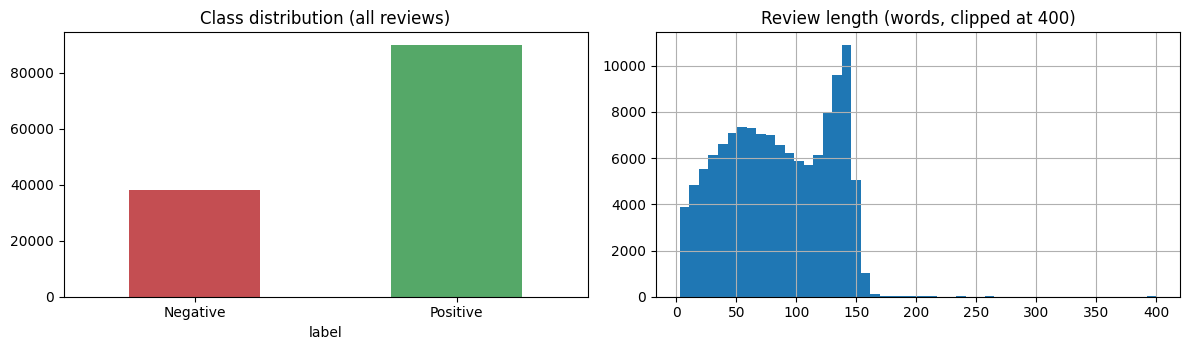

In [4]:
frames = [pd.read_csv(p, sep='\t' if p.endswith('.tsv') else ',') for p in paths]
df = pd.concat(frames, ignore_index=True)
print('raw rows:', len(df))

df = df.dropna(subset=['review', 'rating']).copy()
df['review'] = (df['review'].astype(str).map(html.unescape)
                .str.replace(r'\s+', ' ', regex=True).str.strip().str.strip('"').str.strip())
df = df[df['review'].str.split().str.len() >= 3]
df = df.drop_duplicates(subset='review').reset_index(drop=True)   # same review is listed many times -> leakage
print('after cleaning / de-duplication:', len(df))

df['label'] = (df['rating'] >= 6).astype(int)      # 1-5 -> Negative (0), 6-10 -> Positive (1)
print(pd.crosstab(df['rating'].astype(int), df['label'].map(dict(enumerate(LABELS)))))
print(df['label'].value_counts().sort_index().rename(index=dict(enumerate(LABELS))))

train_df, rest = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=SEED)
val_df, test_df = train_test_split(rest, test_size=0.50, stratify=rest['label'], random_state=SEED)
if MAX_TRAIN and len(train_df) > MAX_TRAIN:
    train_df, _ = train_test_split(train_df, train_size=MAX_TRAIN, stratify=train_df['label'], random_state=SEED)
SPLITS = {'train': train_df.reset_index(drop=True), 'val': val_df.reset_index(drop=True),
          'test': test_df.reset_index(drop=True)}
for k, v in SPLITS.items():
    print(f'{k:5s} {len(v):6d}', v['label'].value_counts().sort_index().to_dict())

names = list(SPLITS)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        assert not set(SPLITS[names[i]]['review']) & set(SPLITS[names[j]]['review'])
print('No text overlap between splits')

# class weights (sqrt of inverse frequency, train split only) -> helps the smaller Negative class
cnt = np.bincount(SPLITS['train']['label'], minlength=NC)
CLASS_W = torch.tensor(np.sqrt(cnt.sum() / (NC * cnt)), dtype=torch.float32)
CLASS_W = CLASS_W / CLASS_W.mean()
print('class weights:', dict(zip(LABELS, CLASS_W.numpy().round(3))))

y_train, y_val, y_test = (SPLITS[k]['label'].values for k in ['train', 'val', 'test'])
for k, v in SPLITS.items():
    np.save(f'{OUT}/labels_{k}.npy', v['label'].values)

# quick EDA
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
df['label'].map(dict(enumerate(LABELS))).value_counts().reindex(LABELS).plot.bar(ax=ax[0], color=['#C44E52', '#55A868'])
ax[0].set_title('Class distribution (all reviews)'); ax[0].tick_params(axis='x', rotation=0)
df['review'].str.split().str.len().clip(upper=400).hist(bins=50, ax=ax[1])
ax[1].set_title('Review length (words, clipped at 400)')
plt.tight_layout(); savefig_auto(); plt.show()

## 3. Shared helpers (metrics, curves, overfitting check, threshold tuning)

In [5]:
def metrics_from(y, probs, bias=None):
    logp = np.log(np.clip(probs, 1e-9, 1))
    pred = (logp + (0 if bias is None else bias)).argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    return dict(acc=accuracy_score(y, pred), macro_p=p, macro_r=r, macro_f1=f, pred=pred)

def tune_bias(y, probs, grid=np.arange(-1.0, 1.01, 0.05)):
    # additive log-prob bias for Negative (Positive fixed at 0) = decision threshold; tuned on VALIDATION only
    best = (metrics_from(y, probs)['macro_f1'], np.zeros(NC))
    for b0 in grid:
        b = np.array([b0, 0.0])
        f = metrics_from(y, probs, b)['macro_f1']
        if f > best[0] + 1e-6: best = (f, b)
    return best[1]

def plot_curves(hist, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    ep = range(1, len(hist['val_f1']) + 1)
    ax[0].plot(ep, hist['train_loss'], 'o-', label='train'); ax[0].plot(ep, hist['val_loss'], 'o-', label='val'); ax[0].set_title(title + ' – loss')
    ax[1].plot(ep, hist['train_f1'], 'o-', label='train'); ax[1].plot(ep, hist['val_f1'], 'o-', label='val'); ax[1].set_title(title + ' – macro-F1')
    ax[2].plot(ep, hist['train_acc'], 'o-', label='train'); ax[2].plot(ep, hist['val_acc'], 'o-', label='val'); ax[2].set_title(title + ' – accuracy')
    for a in ax: a.legend(); a.set_xlabel('epoch')
    plt.tight_layout(); savefig_auto(); plt.show()

def overfit_report(hist, name):
    b = int(np.argmax(hist['val_f1']))
    gap = hist['train_f1'][b] - hist['val_f1'][b]
    print(f'[{name}] best epoch = {b+1}/{len(hist["val_f1"])} | val macro-F1 = {hist["val_f1"][b]:.4f} | '
          f'train-val macro-F1 gap = {gap:.3f}')
    print('  -> OK: no meaningful overfitting' if gap < 0.08 else
          '  -> NOTE: noticeable gap; early stopping keeps the best-validation checkpoint')
    return gap

def new_hist(): return {k: [] for k in ['train_loss', 'val_loss', 'train_acc', 'val_acc', 'train_f1', 'val_f1']}

# fixed random subset of the training set, evaluated in eval-mode -> fair train vs val comparison
SUB_IDX = np.random.RandomState(0).choice(len(SPLITS['train']), min(8000, len(SPLITS['train'])), replace=False)
n_params = lambda m: sum(p.numel() for p in m.parameters())
RESULTS = {}      # name -> dict(probs per split, hist, params, train_time)

## 4. Model 1 – BiLSTM (sequence learning)

vocab size: 27667
ep01 train_loss 0.306 val_loss 0.332 | train_F1 0.849 val_F1 0.828 val_acc 0.854 | lr 2.0e-03
ep02 train_loss 0.262 val_loss 0.306 | train_F1 0.879 val_F1 0.841 val_acc 0.869 | lr 2.0e-03
ep03 train_loss 0.223 val_loss 0.294 | train_F1 0.901 val_F1 0.848 val_acc 0.873 | lr 2.0e-03
ep04 train_loss 0.204 val_loss 0.295 | train_F1 0.920 val_F1 0.850 val_acc 0.874 | lr 2.0e-03
ep05 train_loss 0.200 val_loss 0.318 | train_F1 0.920 val_F1 0.844 val_acc 0.865 | lr 2.0e-03
ep06 train_loss 0.173 val_loss 0.301 | train_F1 0.946 val_F1 0.847 val_acc 0.873 | lr 1.0e-03
ep07 train_loss 0.142 val_loss 0.317 | train_F1 0.956 val_F1 0.846 val_acc 0.870 | lr 1.0e-03
Early stopping
[BiLSTM] best epoch = 4/7 | val macro-F1 = 0.8500 | train-val macro-F1 gap = 0.070
  -> OK: no meaningful overfitting


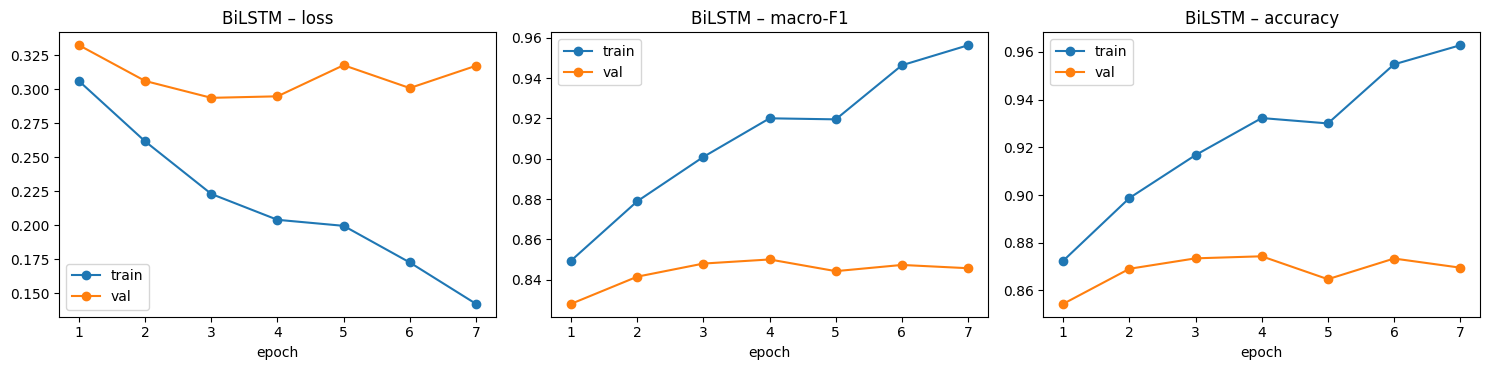

In [6]:
def tokenize(t):
    return re.findall(r"[a-z0-9']+|[!?]", t.lower())

MAX_VOCAB = 40000
counter = Counter(tok for t in SPLITS['train']['review'] for tok in tokenize(t))     # TRAIN only
vocab = {'<pad>': 0, '<unk>': 1}
for w, c in counter.most_common(MAX_VOCAB - 2):
    if c >= 2: vocab[w] = len(vocab)
print('vocab size:', len(vocab))

def encode(t):
    ids = [vocab.get(w, 1) for w in tokenize(t)][:LSTM_MAX_LEN]
    return ids if ids else [1]

class LSTMData(Dataset):
    def __init__(self, df): self.x = [encode(t) for t in df['review']]; self.y = df['label'].values
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], int(self.y[i])

def lstm_collate(batch):
    lens = torch.tensor([len(x) for x, _ in batch])
    X = torch.zeros(len(batch), int(lens.max()), dtype=torch.long)
    for i, (x, _) in enumerate(batch): X[i, :len(x)] = torch.tensor(x)
    return X, lens, torch.tensor([y for _, y in batch])

class BiLSTM(nn.Module):
    def __init__(self, V, emb=200, hid=128, layers=2, nc=NC, emb_drop=0.3, drop=0.4):
        super().__init__()
        self.emb = nn.Embedding(V, emb, padding_idx=0)
        self.emb_drop = nn.Dropout(emb_drop)
        self.lstm = nn.LSTM(emb, hid, num_layers=layers, batch_first=True, bidirectional=True, dropout=0.3)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(hid * 4, nc)            # [max-pool ; mean-pool] of 2*hid each
    def forward(self, x, lens):
        e = self.emb_drop(self.emb(x))
        packed = pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (x != 0).unsqueeze(-1)
        mx = out.masked_fill(~mask, -1e4).max(1).values
        mean = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(self.drop(torch.cat([mx, mean], 1)))

lstm_sets = {k: LSTMData(v) for k, v in SPLITS.items()}
mk = lambda ds, shuffle, bs=128: DataLoader(ds, batch_size=bs, shuffle=shuffle, collate_fn=lstm_collate)
lstm_loaders = {k: mk(ds, k == 'train') for k, ds in lstm_sets.items()}
lstm_eval = {k: mk(ds, False, 512) for k, ds in lstm_sets.items()}
lstm_train_sub = mk(Subset(lstm_sets['train'], SUB_IDX), False, 512)

@torch.no_grad()
def lstm_predict(model, loader):
    model.eval(); P, Y, L = [], [], 0.0
    for X, lens, y in loader:
        logits = model(X.to(DEVICE), lens)
        L += F.cross_entropy(logits, y.to(DEVICE), reduction='sum').item()
        P.append(F.softmax(logits, -1).cpu().numpy()); Y.append(y.numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    return L / len(Y), P, Y

set_seed()
lstm = BiLSTM(len(vocab)).to(DEVICE)
opt = torch.optim.AdamW(lstm.parameters(), lr=2e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=1)
EPOCHS, PATIENCE = 15, 3
w_dev = CLASS_W.to(DEVICE)
hist = new_hist(); best_f1, best_state, bad = -1, None, 0
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    lstm.train()
    for X, lens, y in lstm_loaders['train']:
        opt.zero_grad()
        loss = F.cross_entropy(lstm(X.to(DEVICE), lens), y.to(DEVICE), weight=w_dev, label_smoothing=0.05)
        loss.backward(); nn.utils.clip_grad_norm_(lstm.parameters(), 1.0); opt.step()
    tl, tp, ty = lstm_predict(lstm, lstm_train_sub)
    vl, vp, vy = lstm_predict(lstm, lstm_eval['val'])
    tm, vm = metrics_from(ty, tp), metrics_from(vy, vp)
    for k, v in zip(hist, [tl, vl, tm['acc'], vm['acc'], tm['macro_f1'], vm['macro_f1']]): hist[k].append(v)
    sched.step(vm['macro_f1'])
    print(f"ep{ep:02d} train_loss {tl:.3f} val_loss {vl:.3f} | train_F1 {tm['macro_f1']:.3f} val_F1 {vm['macro_f1']:.3f} "
          f"val_acc {vm['acc']:.3f} | lr {opt.param_groups[0]['lr']:.1e}")
    if vm['macro_f1'] > best_f1:
        best_f1, bad = vm['macro_f1'], 0
        best_state = copy.deepcopy(lstm.state_dict())
    else:
        bad += 1
        if bad >= PATIENCE: print('Early stopping'); break
lstm_time = time.time() - t0
lstm.load_state_dict(best_state)
overfit_report(hist, 'BiLSTM'); plot_curves(hist, 'BiLSTM')

RESULTS['BiLSTM'] = dict(hist=hist, params=n_params(lstm), train_time=lstm_time,
                         probs={k: lstm_predict(lstm, lstm_eval[k])[1] for k in ['val', 'test']})

## 5. Shared fine-tuning recipe for the Transformer models

In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, get_linear_schedule_with_warmup

class TFData(Dataset):
    def __init__(self, df, tok):
        enc = tok(df['review'].tolist(), truncation=True, max_length=TF_MAX_LEN)
        self.ids, self.att, self.y = enc['input_ids'], enc['attention_mask'], df['label'].values
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return {'input_ids': self.ids[i], 'attention_mask': self.att[i], 'labels': int(self.y[i])}

@torch.no_grad()
def tf_predict(model, loader):
    model.eval(); P, Y, L = [], [], 0.0
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items()}
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=b['input_ids'], attention_mask=b['attention_mask']).logits
        logits = logits.float()
        L += F.cross_entropy(logits, b['labels'], reduction='sum').item()
        P.append(F.softmax(logits, -1).cpu().numpy()); Y.append(b['labels'].cpu().numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    return L / len(Y), P, Y

def finetune_transformer(model_name, epochs=3, patience=1, lr=2e-5, bs=32, warmup=0.1,
                         weight_decay=0.01, label_smoothing=0.1, cls_dropout=0.2):
    set_seed()
    tok = AutoTokenizer.from_pretrained(model_name)
    sets = {k: TFData(v, tok) for k, v in SPLITS.items()}
    col = DataCollatorWithPadding(tok)
    train_loader = DataLoader(sets['train'], batch_size=bs, shuffle=True, collate_fn=col, num_workers=2, pin_memory=USE_AMP)
    ev = lambda ds: DataLoader(ds, batch_size=128, shuffle=False, collate_fn=col, num_workers=2, pin_memory=USE_AMP)
    eval_loaders = {k: ev(sets[k]) for k in ['val', 'test']}
    train_sub = ev(Subset(sets['train'], SUB_IDX))

    extra = {'seq_classif_dropout': cls_dropout} if 'distilbert' in model_name else {'classifier_dropout': cls_dropout}
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=NC, **extra).to(DEVICE)
    no_decay = ['bias', 'LayerNorm.weight', 'layer_norm.weight']
    groups = [{'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], 'weight_decay': weight_decay},
              {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], 'weight_decay': 0.0}]
    opt = torch.optim.AdamW(groups, lr=lr)
    total = epochs * len(train_loader)
    sched = get_linear_schedule_with_warmup(opt, int(warmup * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    w = CLASS_W.to(DEVICE)

    h = new_hist(); best_f1, best_state, bad = -1, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        for step, b in enumerate(train_loader):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=b['input_ids'], attention_mask=b['attention_mask']).logits
            loss = F.cross_entropy(logits.float(), b['labels'], weight=w, label_smoothing=label_smoothing)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            if step % 500 == 0: print(f'  ep{ep} step {step}/{len(train_loader)} loss {loss.item():.3f}')
        tl, tp, ty = tf_predict(model, train_sub)
        vl, vp, vy = tf_predict(model, eval_loaders['val'])
        tm, vm = metrics_from(ty, tp), metrics_from(vy, vp)
        for k, v in zip(h, [tl, vl, tm['acc'], vm['acc'], tm['macro_f1'], vm['macro_f1']]): h[k].append(v)
        print(f"ep{ep} train_loss {tl:.3f} val_loss {vl:.3f} | train_F1 {tm['macro_f1']:.3f} val_F1 {vm['macro_f1']:.3f} val_acc {vm['acc']:.3f}")
        if vm['macro_f1'] > best_f1:
            best_f1, bad = vm['macro_f1'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: print('Early stopping'); break
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    probs = {k: tf_predict(model, eval_loaders[k])[1] for k in ['val', 'test']}
    res = dict(hist=h, params=n_params(model), train_time=train_time, probs=probs)
    del model, opt, best_state; gc.collect()
    if USE_AMP: torch.cuda.empty_cache()
    return res

## 6. Model 2 – DistilBERT

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  ep1 step 0/3203 loss 0.697
  ep1 step 500/3203 loss 0.521
  ep1 step 1000/3203 loss 0.439
  ep1 step 1500/3203 loss 0.445
  ep1 step 2000/3203 loss 0.496
  ep1 step 2500/3203 loss 0.369
  ep1 step 3000/3203 loss 0.512
ep1 train_loss 0.253 val_loss 0.285 | train_F1 0.898 val_F1 0.872 val_acc 0.888
  ep2 step 0/3203 loss 0.324
  ep2 step 500/3203 loss 0.495
  ep2 step 1000/3203 loss 0.350
  ep2 step 1500/3203 loss 0.296
  ep2 step 2000/3203 loss 0.378
  ep2 step 2500/3203 loss 0.304
  ep2 step 3000/3203 loss 0.468
ep2 train_loss 0.202 val_loss 0.282 | train_F1 0.933 val_F1 0.876 val_acc 0.892
  ep3 step 0/3203 loss 0.487
  ep3 step 500/3203 loss 0.270
  ep3 step 1000/3203 loss 0.411
  ep3 step 1500/3203 loss 0.336
  ep3 step 2000/3203 loss 0.241
  ep3 step 2500/3203 loss 0.294
  ep3 step 3000/3203 loss 0.327
ep3 train_loss 0.153 val_loss 0.278 | train_F1 0.957 val_F1 0.881 val_acc 0.900
[DistilBERT] best epoch = 3/3 | val macro-F1 = 0.8812 | train-val macro-F1 gap = 0.076
  -> OK: no m

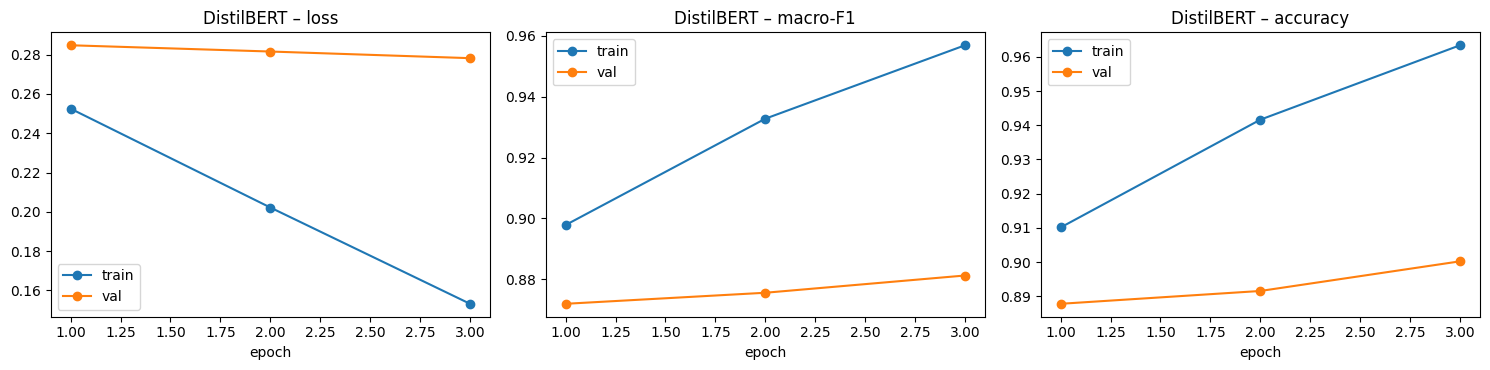

In [9]:
RESULTS['DistilBERT'] = finetune_transformer(DISTIL_NAME, epochs=3, lr=3e-5)
overfit_report(RESULTS['DistilBERT']['hist'], 'DistilBERT'); plot_curves(RESULTS['DistilBERT']['hist'], 'DistilBERT')

## 7. Model 3 – BERT-base

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  ep1 step 0/3203 loss 0.720
  ep1 step 500/3203 loss 0.433
  ep1 step 1000/3203 loss 0.375
  ep1 step 1500/3203 loss 0.438
  ep1 step 2000/3203 loss 0.429
  ep1 step 2500/3203 loss 0.483
  ep1 step 3000/3203 loss 0.355
ep1 train_loss 0.227 val_loss 0.261 | train_F1 0.906 val_F1 0.883 val_acc 0.899
  ep2 step 0/3203 loss 0.421
  ep2 step 500/3203 loss 0.421
  ep2 step 1000/3203 loss 0.336
  ep2 step 1500/3203 loss 0.380
  ep2 step 2000/3203 loss 0.283
  ep2 step 2500/3203 loss 0.336
  ep2 step 3000/3203 loss 0.349
ep2 train_loss 0.170 val_loss 0.249 | train_F1 0.940 val_F1 0.890 val_acc 0.906
  ep3 step 0/3203 loss 0.249
  ep3 step 500/3203 loss 0.345
  ep3 step 1000/3203 loss 0.233
  ep3 step 1500/3203 loss 0.257
  ep3 step 2000/3203 loss 0.426
  ep3 step 2500/3203 loss 0.294
  ep3 step 3000/3203 loss 0.285
ep3 train_loss 0.149 val_loss 0.264 | train_F1 0.959 val_F1 0.888 val_acc 0.906
Early stopping
[BERT-base] best epoch = 2/3 | val macro-F1 = 0.8895 | train-val macro-F1 gap = 0.050

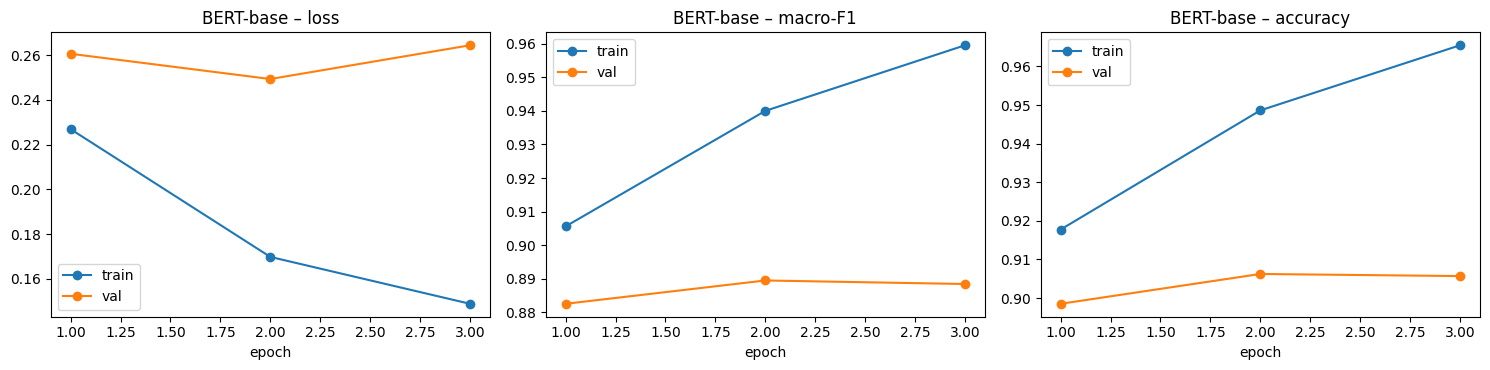

In [10]:
if RUN_BERT_BASE:
    RESULTS['BERT-base'] = finetune_transformer(BERT_NAME, epochs=3, lr=2e-5)
    overfit_report(RESULTS['BERT-base']['hist'], 'BERT-base'); plot_curves(RESULTS['BERT-base']['hist'], 'BERT-base')
else:
    print('BERT-base skipped (RUN_BERT_BASE = False)')

## 8. Final comparison on the held-out test set

In [11]:
MODELS = list(RESULTS); N = len(MODELS)
rows, preds = [], {}
for name in MODELS:
    r = RESULTS[name]
    for k in ['val', 'test']: np.save(f'{OUT}/probs_{name}_{k}.npy', r['probs'][k])
    bias = tune_bias(y_val, r['probs']['val'])                  # decided on validation only
    raw = metrics_from(y_test, r['probs']['test'])
    tm = metrics_from(y_test, r['probs']['test'], bias)
    preds[name] = tm['pred']
    b = int(np.argmax(r['hist']['val_f1']))
    rows.append({'model': name,
                 'test_acc': tm['acc'],
                 'acc_95%CI(+-)': 1.96 * np.sqrt(tm['acc'] * (1 - tm['acc']) / len(y_test)),
                 'macro_precision': tm['macro_p'], 'macro_recall': tm['macro_r'], 'macro_F1': tm['macro_f1'],
                 'macro_F1(argmax)': raw['macro_f1'],
                 'weighted_F1': f1_score(y_test, tm['pred'], average='weighted'),
                 'train-val F1 gap': r['hist']['train_f1'][b] - r['hist']['val_f1'][b],
                 'params(M)': r['params'] / 1e6, 'train_min': r['train_time'] / 60})
tab = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print(tab.round(4).to_string(index=False))
tab.round(4).to_csv(f'{OUT}/model_comparison.csv', index=False)

# paired McNemar (exact binomial), Bonferroni-corrected
alpha = 0.05 / max(1, N * (N - 1) // 2); pvals = {}
print(f'\nPaired McNemar test on the test set (significant if p < {alpha:.4f}):')
for i in range(N):
    for j in range(i + 1, N):
        a, c = preds[MODELS[i]] == y_test, preds[MODELS[j]] == y_test
        only_a, only_c = int((a & ~c).sum()), int((~a & c).sum())
        p = binomtest(only_a, only_a + only_c, 0.5).pvalue if only_a + only_c > 0 else 1.0
        pvals[frozenset({MODELS[i], MODELS[j]})] = p
        print(f'  {MODELS[i]:10s} vs {MODELS[j]:10s}: only-{MODELS[i]} right={only_a:5d}, '
              f'only-{MODELS[j]} right={only_c:5d}, p={p:.2e} -> ' + ('significant' if p < alpha else 'NOT significant'))

val_rank = sorted(MODELS, key=lambda m: -metrics_from(y_val, RESULTS[m]['probs']['val'])['macro_f1'])
top, second = val_rank[0], val_rank[1]
print(f'\nBEST by validation macro-F1: {top} (runner-up: {second})')
if pvals[frozenset({top, second})] < alpha:
    print(f'VERDICT: {top} is significantly better than {second} on the test set.')
else:
    print(f'VERDICT: {top} and {second} are not significantly different -> prefer the cheaper/faster model.')

     model  test_acc  acc_95%CI(+-)  macro_precision  macro_recall  macro_F1  macro_F1(argmax)  weighted_F1  train-val F1 gap  params(M)  train_min
    BiLSTM    0.8691         0.0058           0.8413        0.8505    0.8456            0.8456       0.8700            0.0701     6.2676     7.3404
DistilBERT    0.8995         0.0052           0.8796        0.8804    0.8800            0.8798       0.8996            0.0757    66.9550    28.8511
 BERT-base    0.9011         0.0052           0.8806        0.8840    0.8823            0.8843       0.9013            0.0505   109.4838    57.4192

Paired McNemar test on the test set (significant if p < 0.0167):
  BiLSTM     vs DistilBERT: only-BiLSTM right=  427, only-DistilBERT right=  817, p=9.86e-29 -> significant
  BiLSTM     vs BERT-base : only-BiLSTM right=  385, only-BERT-base right=  795, p=2.46e-33 -> significant
  DistilBERT vs BERT-base : only-DistilBERT right=  313, only-BERT-base right=  333, p=4.55e-01 -> NOT significant

BEST by val

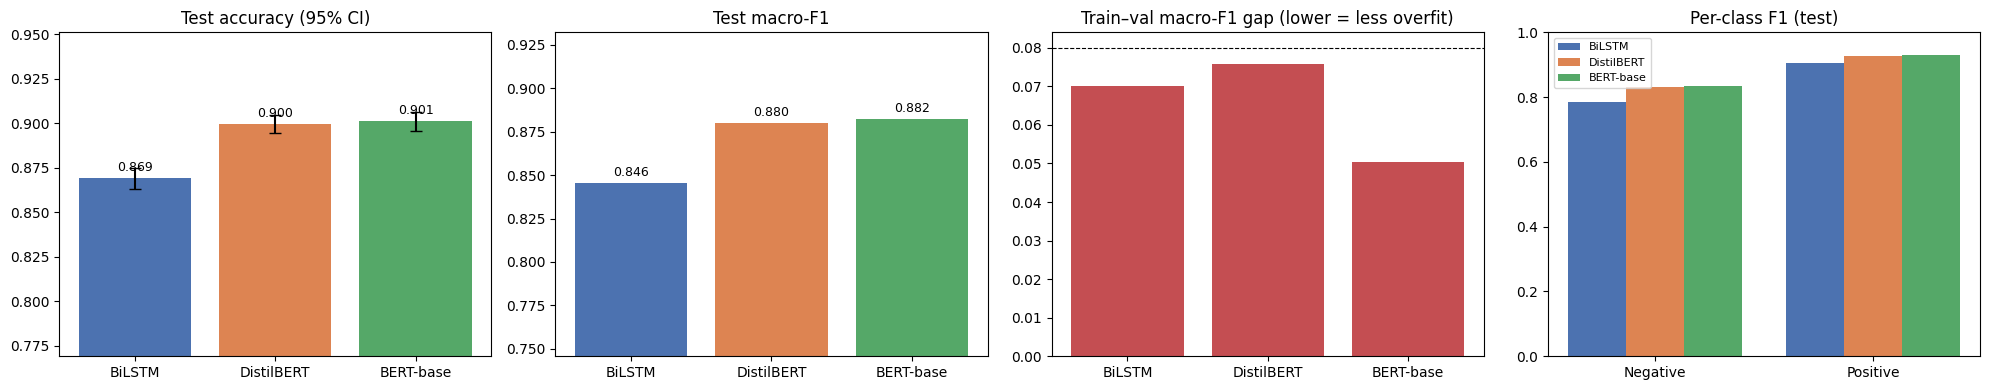

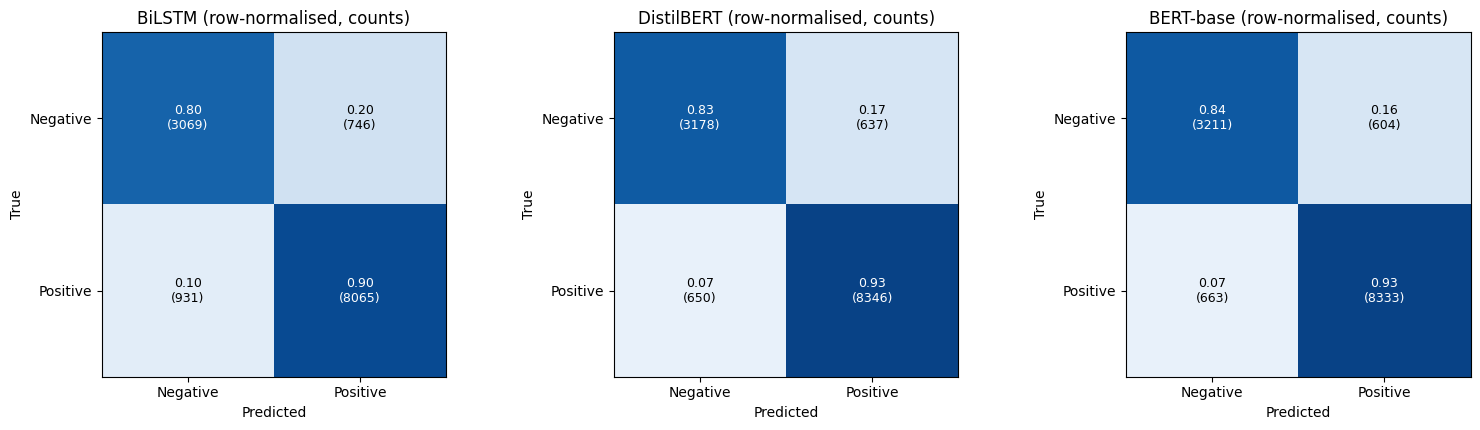


=== BiLSTM ===
              precision    recall  f1-score   support

    Negative      0.767     0.804     0.785      3815
    Positive      0.915     0.897     0.906      8996

    accuracy                          0.869     12811
   macro avg      0.841     0.850     0.846     12811
weighted avg      0.871     0.869     0.870     12811


=== DistilBERT ===
              precision    recall  f1-score   support

    Negative      0.830     0.833     0.832      3815
    Positive      0.929     0.928     0.928      8996

    accuracy                          0.900     12811
   macro avg      0.880     0.880     0.880     12811
weighted avg      0.900     0.900     0.900     12811


=== BERT-base ===
              precision    recall  f1-score   support

    Negative      0.829     0.842     0.835      3815
    Positive      0.932     0.926     0.929      8996

    accuracy                          0.901     12811
   macro avg      0.881     0.884     0.882     12811
weighted avg      0

In [12]:
cols = ['#4C72B0', '#DD8452', '#55A868'][:N]; x = np.arange(N)
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].bar(x, tab['test_acc'], yerr=tab['acc_95%CI(+-)'], capsize=4, color=cols); ax[0].set_title('Test accuracy (95% CI)')
ax[1].bar(x, tab['macro_F1'], color=cols); ax[1].set_title('Test macro-F1')
for a_, v in zip(ax[:2], [tab['test_acc'], tab['macro_F1']]):
    a_.set_xticks(x); a_.set_xticklabels(MODELS); a_.set_ylim(max(0, v.min() - .1), min(1, v.max() + .05))
    for xi, vi in zip(x, v): a_.text(xi, vi + .004, f'{vi:.3f}', ha='center', fontsize=9)
ax[2].bar(x, tab['train-val F1 gap'], color='#C44E52'); ax[2].set_xticks(x); ax[2].set_xticklabels(MODELS)
ax[2].axhline(.08, ls='--', color='k', lw=.8); ax[2].set_title('Train–val macro-F1 gap (lower = less overfit)')
w = .8 / N
for k_, nm in enumerate(MODELS):
    ax[3].bar(np.arange(NC) + (k_ - (N - 1) / 2) * w, f1_score(y_test, preds[nm], average=None), w, label=nm, color=cols[k_])
ax[3].set_xticks(range(NC)); ax[3].set_xticklabels(LABELS); ax[3].set_ylim(0, 1); ax[3].legend(fontsize=8); ax[3].set_title('Per-class F1 (test)')
plt.tight_layout(); savefig_auto(); plt.show()

fig, ax = plt.subplots(1, N, figsize=(5.2 * N, 4.4), squeeze=False); ax = ax[0]
for a_, nm in zip(ax, MODELS):
    cmc = confusion_matrix(y_test, preds[nm]); cm = cmc / cmc.sum(1, keepdims=True)
    a_.imshow(cm, cmap='Blues', vmin=0, vmax=1); a_.set_title(nm + ' (row-normalised, counts)')
    a_.set_xticks(range(NC)); a_.set_xticklabels(LABELS); a_.set_yticks(range(NC)); a_.set_yticklabels(LABELS)
    a_.set_xlabel('Predicted'); a_.set_ylabel('True')
    for i in range(NC):
        for j in range(NC):
            a_.text(j, i, f'{cm[i, j]:.2f}\n({cmc[i, j]})', ha='center', va='center', fontsize=9,
                    color='white' if cm[i, j] > .5 else 'black')
plt.tight_layout(); savefig_auto(); plt.show()

for nm in MODELS:
    print(f'\n=== {nm} ===')
    print(classification_report(y_test, preds[nm], target_names=LABELS, digits=3))

## 9. Error analysis – where do the models disagree?

In [13]:
best = top
err = SPLITS['test'].assign(pred=preds[best])
err = err[err['label'] != err['pred']]
print(f'{best}: {len(err)} test errors. Most common confusions:')
print(err.groupby(['label', 'pred']).size().rename(lambda i: LABELS[i], level=0)
        .rename(lambda i: LABELS[i], level=1).sort_values(ascending=False).to_string())
print('\nSample errors:')
for _, r_ in err.sample(min(6, len(err)), random_state=SEED).iterrows():
    print(f"- rating {r_['rating']:.0f} | true {LABELS[r_['label']]:8s} | pred {LABELS[r_['pred']]:8s} | {r_['review'][:180]}...")

if 'BiLSTM' in preds and best != 'BiLSTM':
    fixed = ((preds['BiLSTM'] != y_test) & (preds[best] == y_test)).sum()
    print(f'\n{best} corrects {fixed} reviews that BiLSTM gets wrong '
          f'({fixed / max(1, (preds["BiLSTM"] != y_test).sum()):.1%} of BiLSTM errors).')

BERT-base: 1267 test errors. Most common confusions:
label     pred    
Positive  Negative    663
Negative  Positive    604

Sample errors:
- rating 5 | true Negative | pred Positive | I suffer from anxiety and have tried several medications in the past. I just started using Buspar 5mg twice daily. I notice in the morning, I am dizzy and have vision problems, it ...
- rating 2 | true Negative | pred Positive | I was taking Lisinopril for about 6 months for my blood pressure which was 150/103...it went down to about 115/70 which is good. But I develped the "ACE cough" like abut 15% of peo...
- rating 6 | true Positive | pred Negative | I am experiencing side effect of diarrhea after 5 day. Still having pain Don't know if it's going to be worth all the diarrhea...
- rating 7 | true Positive | pred Negative | I have been using Zetia for two years. I am also having extreme muscle pain with profuse sweating when I get too hot....
- rating 8 | true Positive | pred Negative | Medicare does no

## 10. Save everything

In [14]:
shutil.make_archive(OUT.rstrip('/') + '_bundle', 'zip', OUT)
print(sorted(os.listdir(OUT)))
if IN_COLAB: files.download(OUT.rstrip('/') + '_bundle.zip')

['fig_01.png', 'fig_02.png', 'fig_03.png', 'fig_04.png', 'fig_05.png', 'fig_06.png', 'labels_test.npy', 'labels_train.npy', 'labels_val.npy', 'model_comparison.csv', 'probs_BERT-base_test.npy', 'probs_BERT-base_val.npy', 'probs_BiLSTM_test.npy', 'probs_BiLSTM_val.npy', 'probs_DistilBERT_test.npy', 'probs_DistilBERT_val.npy']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>